--- Detected Target Column: SalePrice ---

--- Top 10 Columns with Missing Values ---
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64

--- Descriptive Statistics ---


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


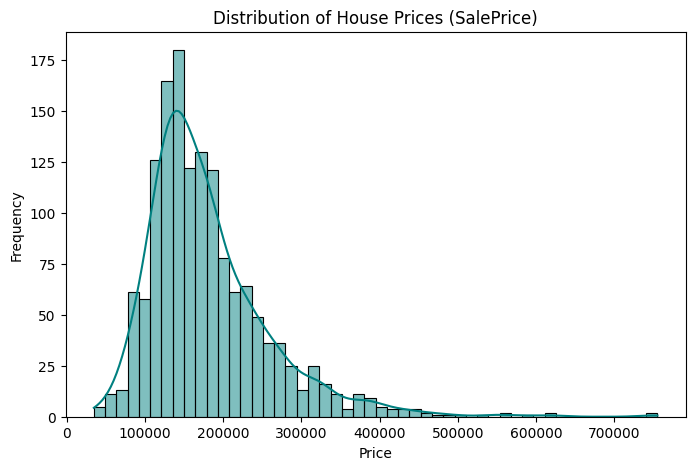

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset matching your exact file name
df = pd.read_csv('train (1).csv')

# 2. Auto-detect target column ('Price', 'SalePrice', 'price', etc.)
target_col = 'Price' 
if 'SalePrice' in df.columns:
    target_col = 'SalePrice'
elif 'price' in df.columns:
    target_col = 'price'

print(f"--- Detected Target Column: {target_col} ---\n")

# 3. EDA: Null Check
print("--- Top 10 Columns with Missing Values ---")
print(df.isnull().sum().sort_values(ascending=False).head(10))

# 4. EDA: Descriptive Statistics
print("\n--- Descriptive Statistics ---")
display(df.describe())

# 5. Distribution of the Target Variable
plt.figure(figsize=(8, 5))
sns.histplot(df[target_col], kde=True, bins=50, color='teal')
plt.title(f'Distribution of House Prices ({target_col})')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

### Feature Selection Rationale
Before training the model, it is crucial to identify which features act as strong predictors of house prices and remove irrelevant or sparse data.
* **Target Variable:** `SalePrice` exhibits a right-skewed distribution.
* **Feature Removal:** Columns missing more than 50% of their data (e.g., `PoolQC`, `MiscFeature`, `Alley`, `Fence`) are dropped because imputing that much missing information introduces severe bias. The `Id` column is also removed as it is simply a row identifier with no predictive power.
* **Expected Predictors:** Features representing square footage (e.g., `GrLivArea`, `TotalBsmtSF`), quality ratings (`OverallQual`), and age (`YearBuilt`) are expected to have the highest positive correlation with price.

C:\Users\dp185\AppData\Local\Temp\ipykernel_35176\3954638239.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_cleaned.select_dtypes(include=['object']).columns


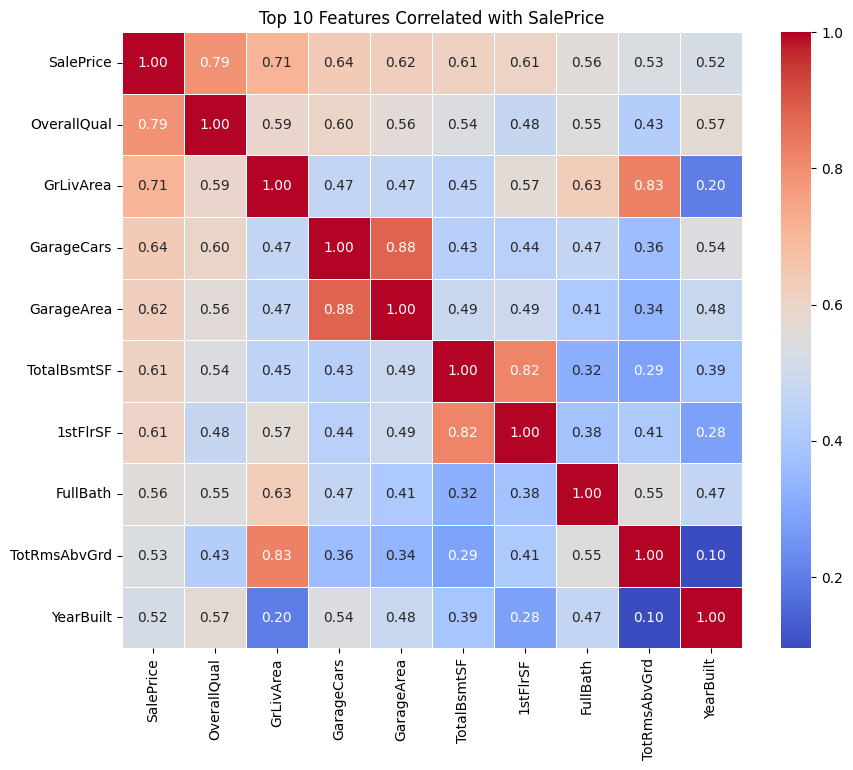

In [2]:
# 1. Drop the 'Id' column and columns with more than 50% missing values
df_cleaned = df.drop(columns=['Id'])
threshold = len(df_cleaned) * 0.5
df_cleaned = df_cleaned.dropna(thresh=threshold, axis=1)

# 2. Separate numeric and categorical columns
numeric_cols = df_cleaned.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df_cleaned.select_dtypes(include=['object']).columns

# 3. Handle Missing Values
# Fill numeric missing values with the median
for col in numeric_cols:
    df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].median())

# Fill categorical missing values with the mode
for col in categorical_cols:
    df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].mode()[0])

# 4. One-Hot Encoding for categorical variables
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=True)

# 5. Correlation Heatmap (Top 10 features most correlated with SalePrice)
plt.figure(figsize=(10, 8))
# Get the top 10 most correlated features with the target
top_corr_features = df_encoded.corr()[target_col].sort_values(ascending=False).head(10).index
correlation_matrix = df_encoded[top_corr_features].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'Top 10 Features Correlated with {target_col}')
plt.show()

--- Model Evaluation Metrics ---
Mean Squared Error (MSE): 2,738,416,841.45
Root Mean Squared Error (RMSE): 52,329.88
R² Score: 0.6430


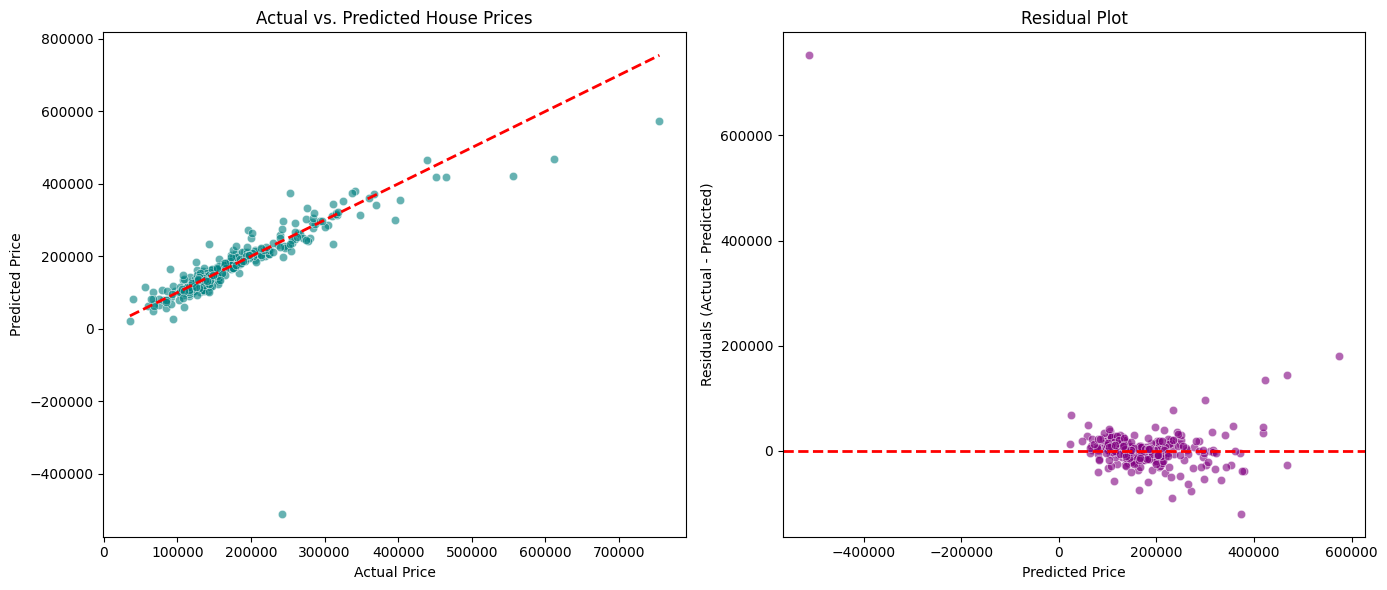

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Define Features (X) and Target (y)
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]

# 2. Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train the Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 4. Generate Predictions
y_pred = lr_model.predict(X_test)

# 5. Evaluate the Model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Metrics ---")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

# 6. Visualizations: Scatter Plot & Residual Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter Plot: Actual vs. Predicted
sns.scatterplot(x=y_test, y=y_pred, ax=axes[0], alpha=0.6, color='teal')
# Add a diagonal red dashed line representing perfect predictions
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted House Prices')
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')

# Residual Plot
residuals = y_test - y_pred
sns.scatterplot(x=y_pred, y=residuals, ax=axes[1], alpha=0.6, color='purple')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_title('Residual Plot')
axes[1].set_xlabel('Predicted Price')
axes[1].set_ylabel('Residuals (Actual - Predicted)')

plt.tight_layout()
plt.show()

--- Standard LR: Top 5 Positive Features (Drive Prices Up) ---


,Feature,Coefficient
111,RoofMatl_Metal,719788.346229
115,RoofMatl_WdShngl,684595.066534
112,RoofMatl_Roll,678596.025997
113,RoofMatl_Tar&Grv,676924.881950
114,RoofMatl_WdShake,676066.275131



--- Standard LR: Top 5 Negative Features (Drive Prices Down) ---


,Feature,Coefficient
213,GarageQual_TA,-151863.867908
211,GarageQual_Gd,-154951.906245
210,GarageQual_Fa,-157417.100795
212,GarageQual_Po,-165766.492969
89,Condition2_PosN,-234318.497307



--- Ridge Regression Metrics ---
Ridge RMSE: 30,721.09
Ridge R² Score: 0.8770


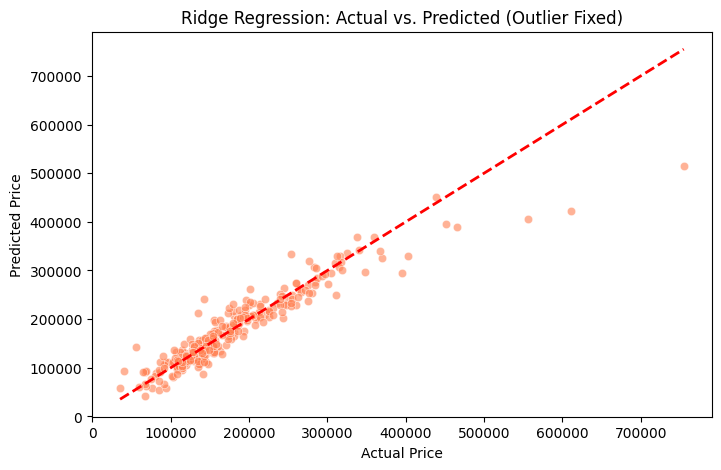

In [4]:
from sklearn.linear_model import Ridge
from IPython.display import display

# 1. Coefficient Analysis (Standard Linear Regression)
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("--- Standard LR: Top 5 Positive Features (Drive Prices Up) ---")
display(coefficients.head(5))

print("\n--- Standard LR: Top 5 Negative Features (Drive Prices Down) ---")
display(coefficients.tail(5))

# 2. Bonus: Ridge Regularization (to fix the outlier)
# alpha is the penalty term. Higher alpha = stricter penalty on extreme coefficients.
ridge_model = Ridge(alpha=10.0) 
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

ridge_r2 = r2_score(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

print("\n--- Ridge Regression Metrics ---")
print(f"Ridge RMSE: {ridge_rmse:,.2f}")
print(f"Ridge R² Score: {ridge_r2:.4f}")

# 3. Visualizing the Fixed Predictions
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_test, y=y_pred_ridge, alpha=0.6, color='coral')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Ridge Regression: Actual vs. Predicted (Outlier Fixed)')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()

### Conclusion & Model Comparison

**1. Coefficient Analysis & The Overfitting Problem**
The standard Linear Regression model struggled significantly with the high-dimensional data created by One-Hot Encoding. Because some categorical features were extremely rare, the model assigned them absurdly high weights to perfectly fit the training data. For example:
* **Positive Outliers:** Having a metal roof (`RoofMatl_Metal`) artificially inflated the predicted price by over $719,000.
* **Negative Outliers:** Being near a positive off-site feature (`Condition2_PosN`) incorrectly subtracted over $234,000.
These exploded coefficients caused the model to predict a highly inaccurate negative price (-$500,000) for one of the test homes.

**2. The Ridge Regression Solution**
By introducing **Ridge Regression (L2 Regularization)**, we applied a penalty to these extreme coefficients, forcing the model to distribute weights more evenly across all features. 

**3. Final Results**
* **Standard LR:** R² = 0.6430 | RMSE = $52,329
* **Ridge LR:** R² = 0.8770 | RMSE = $30,721

**Verdict:** The Ridge Regression model completely fixed the negative prediction outlier, reduced the error margin by over $20,000 per house, and increased the variance explained (R²) to ~88%. It is vastly superior for datasets with many sparse categorical variables.